In [3]:
import pandas as pd
import matplotlib.pyplot as plt

Import data and define agegroups

In [4]:
df = pd.read_csv('Titanic.csv')
Agebins   = [0, 10, 16, 30, 50, 100]
Agelabels = ["0-10", "11-16", "17-30", "31-50", "51+"]

df["Agegroup"] = pd.cut(df["Age"], bins=Agebins, labels=Agelabels)
df["Agegroup"] = df["Agegroup"].cat.add_categories("Unknown").fillna("Unknown")


df["Agegroup"].value_counts()


Agegroup
17-30      309
31-50      241
Unknown    177
0-10        64
51+         64
11-16       36
Name: count, dtype: int64

In [11]:
rates = df.groupby(["Agegroup", "Sex"])["Survived"].mean()
print(rates)
rates = rates.unstack()
print(rates)
counts = df.groupby(["Agegroup", "Sex"], observed=True)["Survived"].size().unstack()
print(counts)

Agegroup  Sex   
0-10      female    0.612903
          male      0.575758
11-16     female    0.777778
          male      0.166667
17-30     female    0.743119
          male      0.150000
31-50     female    0.779070
          male      0.225806
51+       female    0.941176
          male      0.127660
Unknown   female    0.679245
          male      0.129032
Name: Survived, dtype: float64
Sex         female      male
Agegroup                    
0-10      0.612903  0.575758
11-16     0.777778  0.166667
17-30     0.743119  0.150000
31-50     0.779070  0.225806
51+       0.941176  0.127660
Unknown   0.679245  0.129032
Sex       female  male
Agegroup              
0-10          31    33
11-16         18    18
17-30        109   200
31-50         86   155
51+           17    47
Unknown       53   124


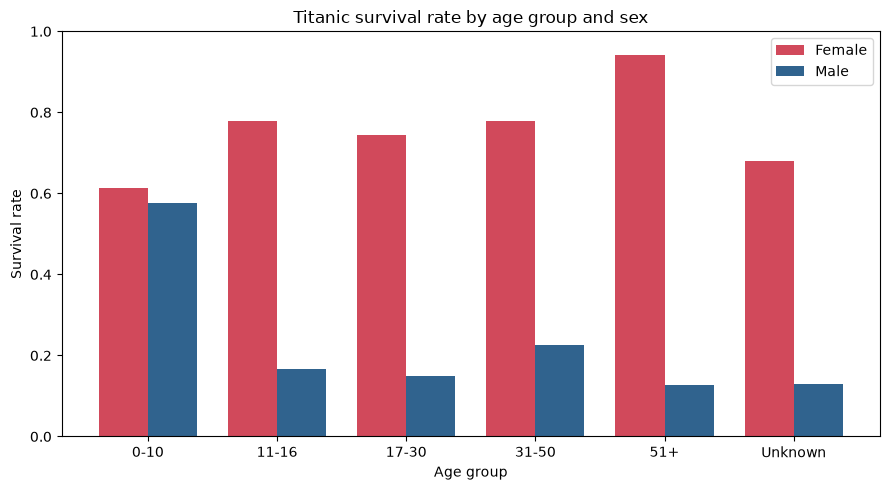

In [14]:
import numpy as np
import matplotlib.pyplot as plt

groups = rates.index.tolist()
x = np.arange(len(groups))   # positions 0,1,2,3,4,5
w = 0.38                     # bar width

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x - w/2, rates["female"], w, label="Female", color="#d1495b")
ax.bar(x + w/2, rates["male"],   w, label="Male",   color="#30638e")

ax.set_xticks(x)
ax.set_xticklabels(groups)
ax.set_ylabel("Survival rate")
ax.set_xlabel("Age group")
ax.set_title("Titanic survival rate by age group and sex")
ax.set_ylim(0, 1)
ax.legend()
plt.tight_layout()
plt.show()